# RAFDB data perparation notebook

Data source: http://www.whdeng.cn/RAF/model1.html

The data is split into basic and compound folders for basic emotions and compound emotions. 

We will be omitting the compound emotions and focus on the basic emotions.
```text

basic:
|
|---Annotation
|---EmoLabel
|---Feature
|---Image
|---README.txt


In [1]:
import torchvision.transforms.v2 as v2
import torch
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os, shutil
os.chdir('..')
from utility_scripts.adaface_utils.face_alignment.align import get_aligned_face

In [2]:
aligned_images_path = os.path.join('data', 'datasets', 'emotion recognition', 'RAF_DB', 'RAF_DB','basic', 'Image', 'aligned')
os.path.exists(aligned_images_path)

True

In [3]:
labels_path = os.path.join('data', 'datasets', 'emotion recognition', 'RAF_DB', 'RAF_DB', 'basic', 'EmoLabel', 'list_patition_label.txt')
os.path.exists(labels_path)

True

In [4]:
image_paths = []
for image_path in sorted(os.listdir(aligned_images_path)):
    image_paths.append(os.path.join(aligned_images_path, image_path))

In [5]:
label_translation_to_affectnet = { # translated the labels from the RAF format to the AffectNet format
    0 : 3,
    1 : 4,
    2 : 5,
    3 : 1,
    4 : 2,
    5 : 6,
    6 : 0
}

affectnet_to_raf = {v : k for k, v in label_translation_to_affectnet.items()}
permute_indices = [affectnet_to_raf[i] for i in range(7)]

label_translation_to_text = {
    0 : 'neutral',
    1 : 'happy',
    2 : 'sad',
    3 : 'surprise',
    4 : 'fear',
    5 : 'disgust',
    6 : 'anger'
}

In [6]:
from utility_scripts.poster_v2_code.models.PosterV2_7cls import *

poster_model = get_poster_v2_model(os.path.join('data', 'models', 'poster_v2_models', 'raf-db-model_best.pth'))
poster_transform = v2.Compose([
    v2.Resize(size = (224, 224)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale = True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

/home/thoal/anaconda3/envs/pytorch/lib/python3.13/site-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/home/thoal/anaconda3/envs/pytorch/lib/python3.13/site-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)


load_weight 304


/home/thoal/anaconda3/envs/pytorch/lib/python3.13/site-packages/torch/functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4322.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


load_weight 747


In [7]:
with open(labels_path, 'r', encoding = 'utf8') as labels_file:
    lines = sorted(labels_file.readlines())

labels = []
original_labels = []
translated_labels = []
train_test_splits = []
image_names = []
for line in lines:
    line = line.replace('\n', '')
    image_name, label = line.split(' ')
    split = 'train' if 'train' in image_name else 'test'
    
    image_name, file_type = image_name.split('.')
    image_name = image_name + '_aligned.' + file_type
    image_names.append(image_name)
    labels.append(label_translation_to_affectnet[int(label) - 1])
    original_labels.append(int(label) - 1)
    translated_labels.append(label_translation_to_text[labels[-1]])
    train_test_splits.append(split)

### Align and save the images

In [8]:
import cv2

In [9]:
output_dir = os.path.join('data', 'datasets', 'emotion recognition', 'RAF_DB', 'Images')
os.makedirs(output_dir, exist_ok = True)

In [11]:
soft_labels = {
    '0' : [],
    '1' : [],
    '2' : [],
    '3' : [],
    '4' : [],
    '5' : [],
    '6' : []
}
poster_model.to('cuda')
for i, image_name in enumerate(image_names):
    image_path = os.path.join(aligned_images_path, image_name)
    image = cv2.imread(image_path)
    image = cv2.resize(image, (112, 112))
    cv2.imwrite(os.path.join(output_dir, image_name), image)
    
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    
    with torch.no_grad():
        image = poster_transform(image)
        image = image.to('cuda')
        prediction = poster_model(torch.reshape(image, (1, 3, 112, 112)))
        prediction = prediction[:, permute_indices]

        prediction = prediction.squeeze().detach().cpu().numpy()
        for j, pred in enumerate(prediction):
            soft_labels[str(j)].append(pred)
    
    print(i, len(image_names))



0 15339
1 15339
2 15339
3 15339
4 15339
5 15339
6 15339
7 15339
8 15339
9 15339
10 15339
11 15339
12 15339
13 15339
14 15339
15 15339
16 15339
17 15339
18 15339
19 15339
20 15339
21 15339
22 15339
23 15339
24 15339
25 15339
26 15339
27 15339
28 15339
29 15339
30 15339
31 15339
32 15339
33 15339
34 15339
35 15339
36 15339
37 15339
38 15339
39 15339
40 15339
41 15339
42 15339
43 15339
44 15339
45 15339
46 15339
47 15339
48 15339
49 15339
50 15339
51 15339
52 15339
53 15339
54 15339
55 15339
56 15339
57 15339
58 15339
59 15339
60 15339
61 15339
62 15339
63 15339
64 15339
65 15339
66 15339
67 15339
68 15339
69 15339
70 15339
71 15339
72 15339
73 15339
74 15339
75 15339
76 15339
77 15339
78 15339
79 15339
80 15339
81 15339
82 15339
83 15339
84 15339
85 15339
86 15339
87 15339
88 15339
89 15339
90 15339
91 15339
92 15339
93 15339
94 15339
95 15339
96 15339
97 15339
98 15339
99 15339
100 15339
101 15339
102 15339
103 15339
104 15339
105 15339
106 15339
107 15339
108 15339
109 15339
110 15339


In [13]:
soft_labels

{'0': [np.float32(-2.5620747),
  np.float32(4.4884205),
  np.float32(2.62442),
  np.float32(0.10638955),
  np.float32(-1.4392506),
  np.float32(4.0538654),
  np.float32(-1.5063276),
  np.float32(-1.8468771),
  np.float32(-1.3233072),
  np.float32(-2.679228),
  np.float32(0.46259692),
  np.float32(-1.4124968),
  np.float32(-1.9440066),
  np.float32(-1.8277221),
  np.float32(0.8626668),
  np.float32(-0.58218086),
  np.float32(-0.76163775),
  np.float32(-1.6581469),
  np.float32(-1.1555345),
  np.float32(-1.0172297),
  np.float32(1.1659123),
  np.float32(-1.9018047),
  np.float32(-3.2774255),
  np.float32(4.646943),
  np.float32(-2.8338456),
  np.float32(-1.990341),
  np.float32(-2.4228513),
  np.float32(4.9517956),
  np.float32(0.6418128),
  np.float32(-1.4418862),
  np.float32(-4.1120605),
  np.float32(-1.4174823),
  np.float32(-1.0926697),
  np.float32(-1.1612302),
  np.float32(4.593623),
  np.float32(0.87484396),
  np.float32(-1.7387414),
  np.float32(-2.005053),
  np.float32(2.638589

In [14]:
labels_df = pd.DataFrame(
    data = {
        'filename' : image_names,
        'label' : labels,
        **soft_labels,
        'translated' : translated_labels,
        'split' : train_test_splits
    }
)

labels_df.to_csv(
    os.path.join(os.path.split(output_dir)[0], 'labels.csv'),
    index = False
)

# EDA

In [15]:
labels_df = pd.read_csv(os.path.join('data', 'datasets', 'emotion recognition', 'RAF_DB', 'labels.csv'))

In [16]:
labels_df.head()

,filename,label,0,1,2,3,4,5,6,translated,split
0,test_0001_aligned.jpg,2,-2.562075,-2.480328,8.820706,-2.519452,0.043628,-1.624667,-2.026960,sad,test
1,test_0002_aligned.jpg,3,4.488421,-4.236543,-0.379256,6.310108,-0.907672,-2.216257,-3.177683,surprise,test
2,test_0003_aligned.jpg,1,2.624420,5.532173,3.447752,-1.880543,-5.158679,-2.497150,-5.675291,happy,test
3,test_0004_aligned.jpg,3,0.106390,-1.064882,-2.520555,9.360311,-1.827424,-1.923004,-0.561454,surprise,test
4,test_0005_aligned.jpg,2,-1.439251,-2.450538,8.933860,-2.516058,-2.152685,-1.191713,-2.120966,sad,test


In [17]:
len(labels_df)

15339

In [18]:
np.unique(labels_df['split'], return_counts = True)

(array(['test', 'train'], dtype=object), array([ 3068, 12271]))

In [19]:
classes, counts = np.unique(labels_df.label, return_counts = True)

In [20]:
sorted_idx = np.argsort(counts)
classes = classes[sorted_idx]
classes = [label_translation_to_text[cls] for cls in classes]
counts = counts[sorted_idx]


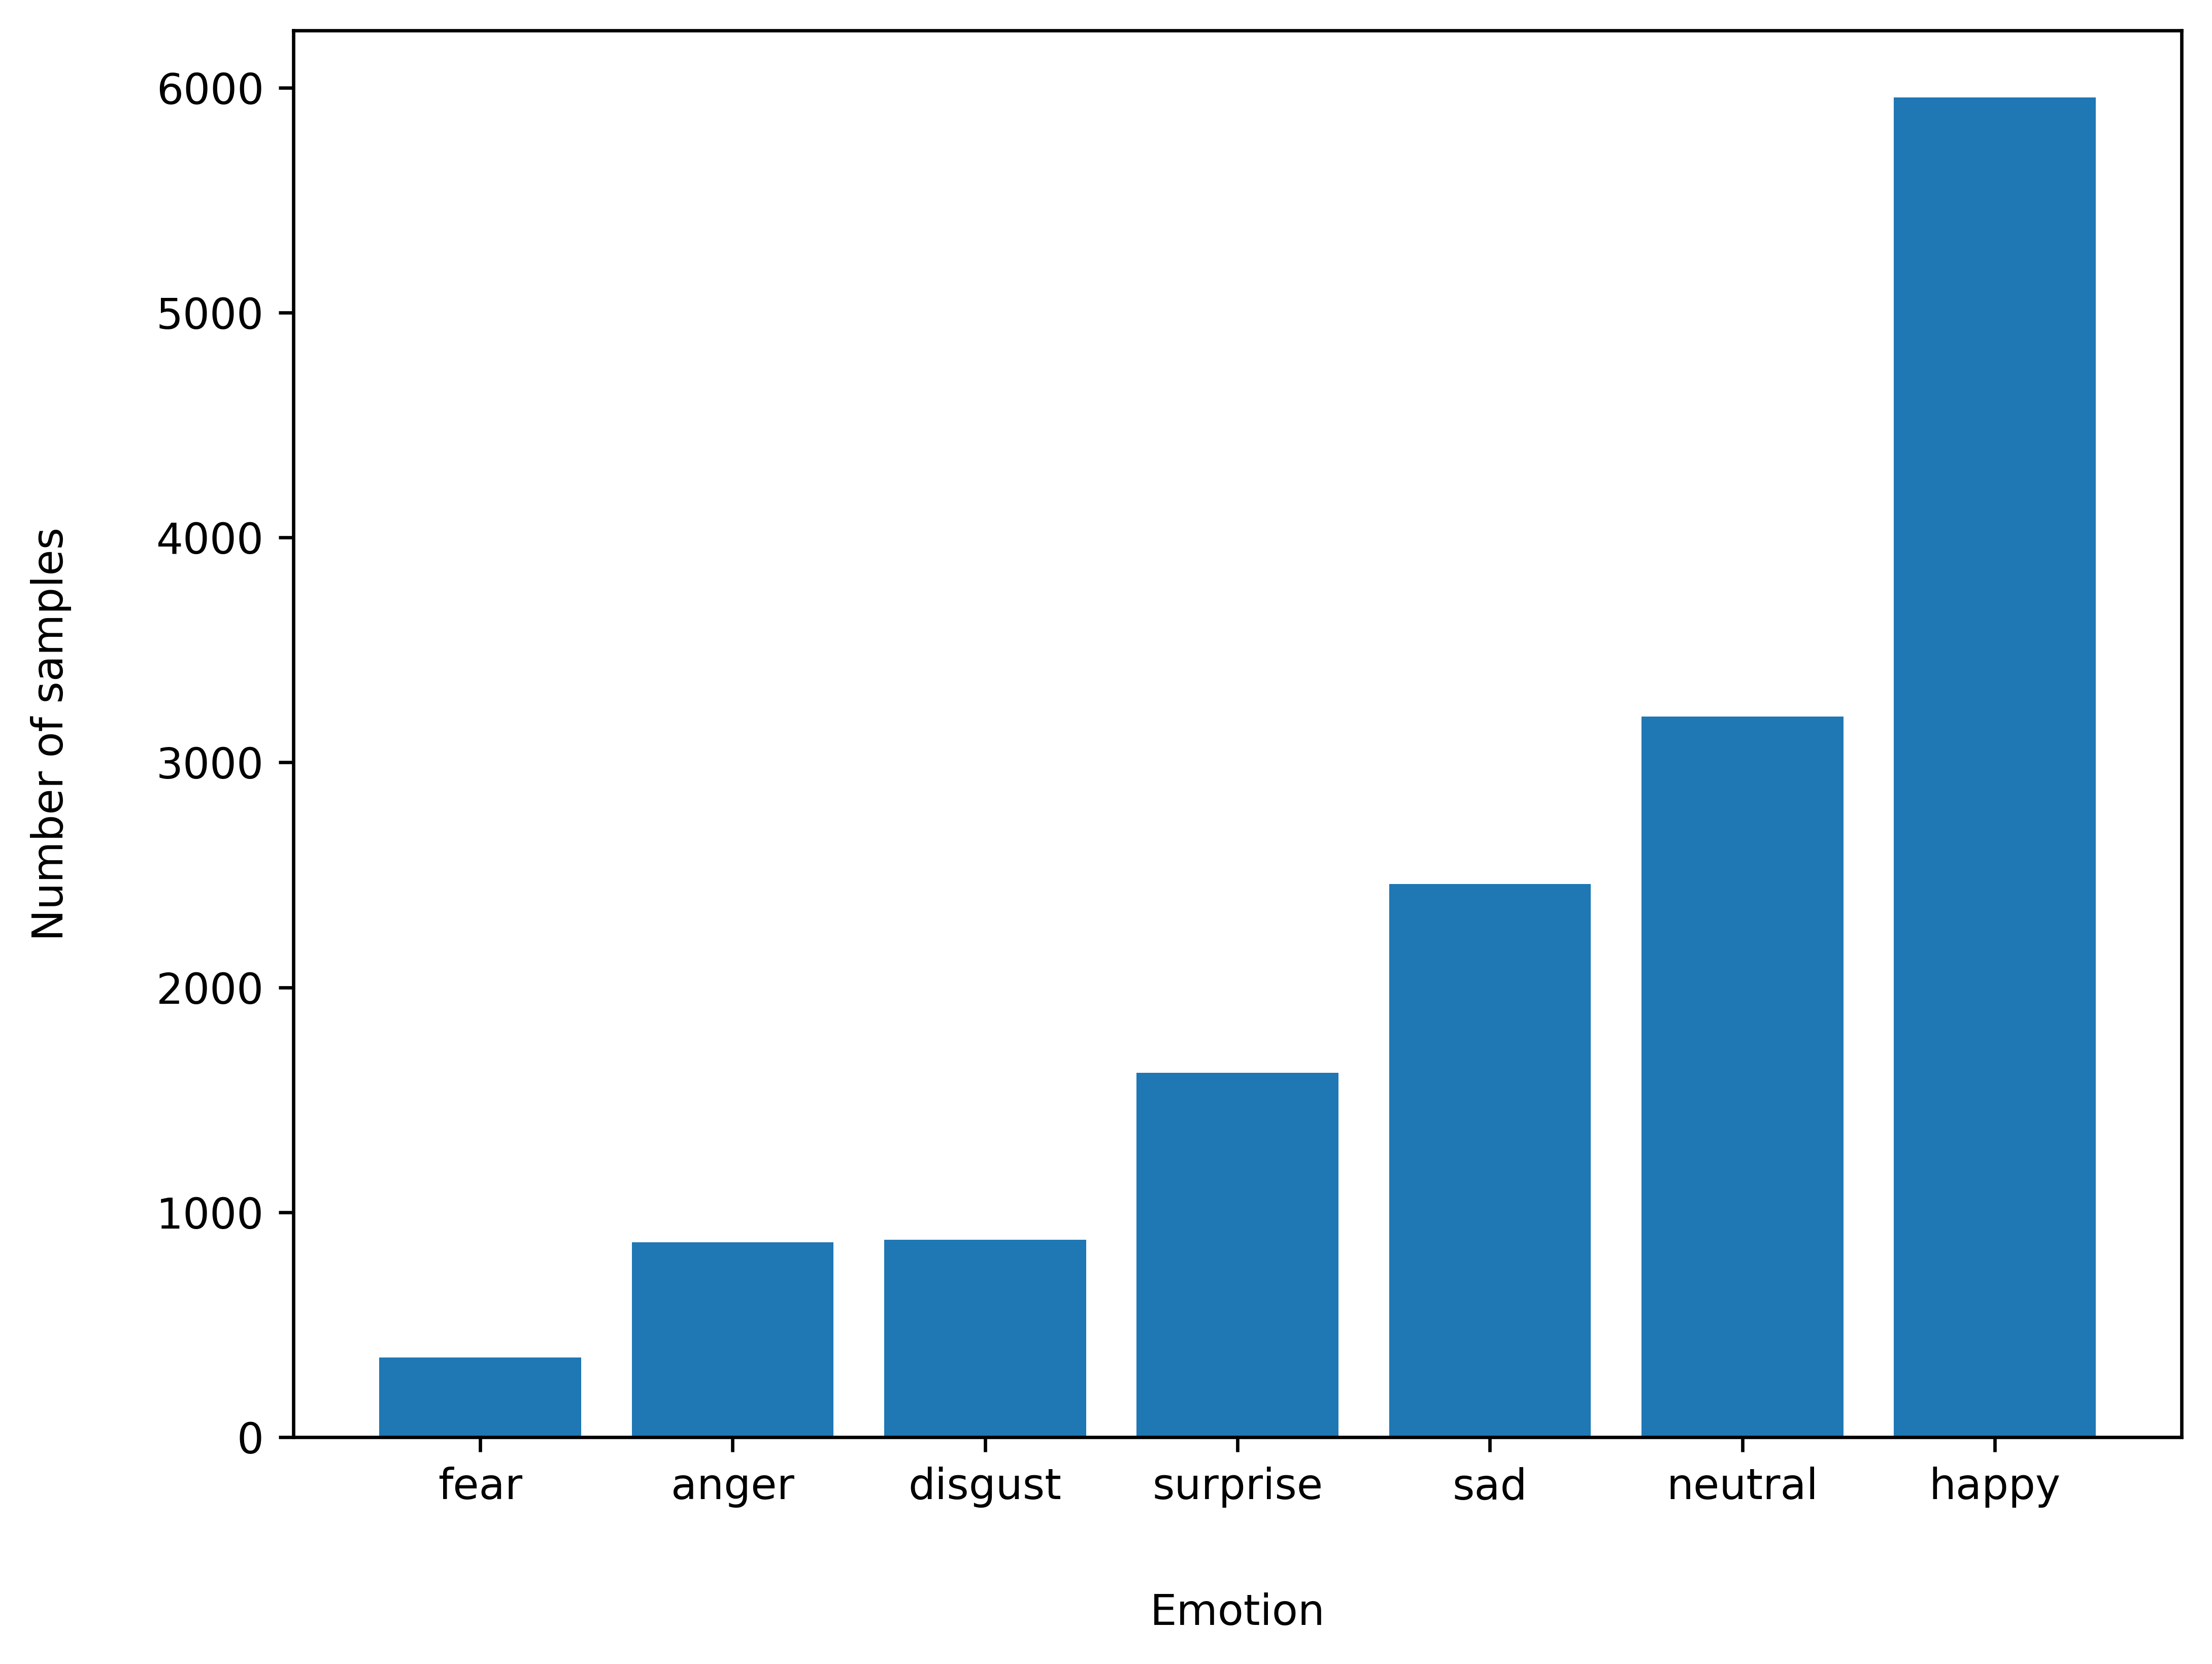

In [21]:
plt.figure(figsize = (8, 6), dpi = 600)
plt.bar(classes, counts)
plt.xlabel('Emotion', labelpad = 20)
plt.ylabel('Number of samples', labelpad = 20)
plt.savefig(
    os.path.join('data', 'figures', 'Emotion Recognition', 'RAF-DB', 'The distribution of classes for RAF-DB')
)
plt.show()

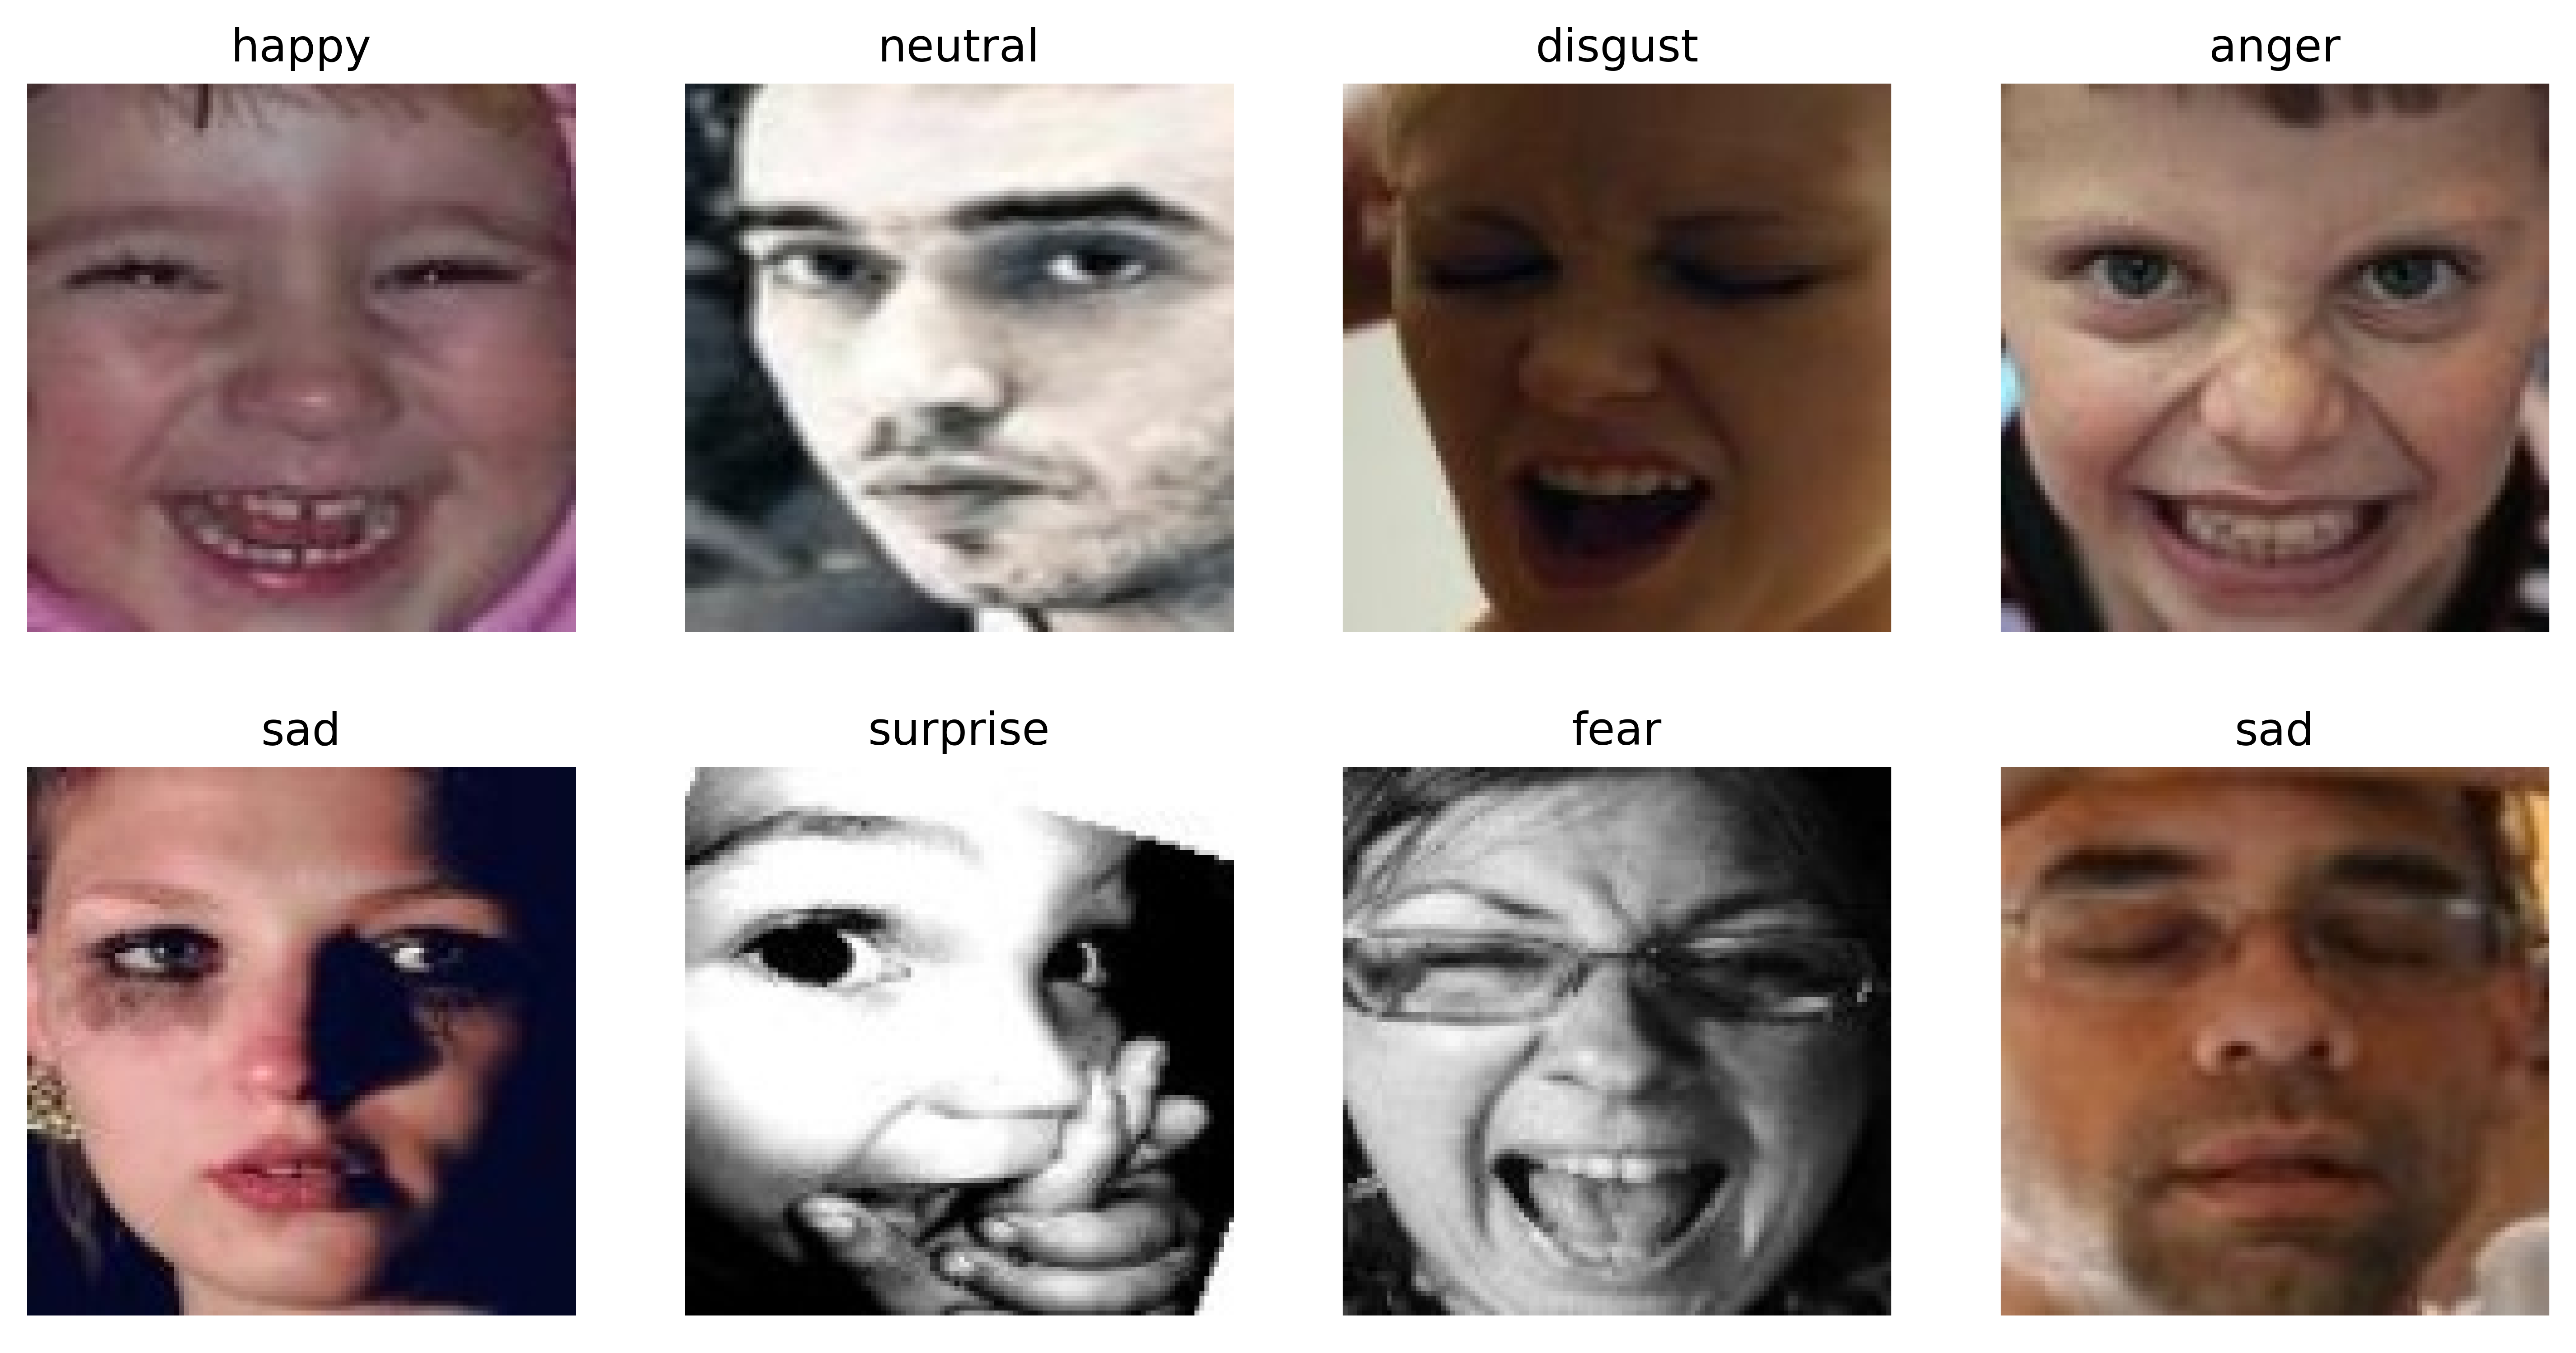

In [22]:
plt.figure(figsize = (12, 6), dpi = 600)
plt.axis('off')

chosen_labels = []
for i in range(8):
    idx = np.random.randint(low = 0, high =len(labels_df))
    label = labels_df['label'][idx]
    while label in chosen_labels: # make sure to show emotions that haven't been shown
        idx = np.random.randint(low = 0, high =len(labels_df))
        label = labels_df['label'][idx]

        if len(chosen_labels) == 7: # since there are only 7 emotions to show, break out of the loop if we got them all
            break
    chosen_labels.append(label)

    filename = labels_df['filename'][idx]
    image = plt.imread(os.path.join(output_dir, filename))
    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.axis('off')
    plt.title(f'{label_translation_to_text[label]}')
plt.savefig(
    os.path.join('data', 'figures', 'Emotion Recognition', 'RAF-DB', 'Sample images from RAF-DB')
)
plt.show()

In [23]:
test_labels = labels_df['label'][labels_df['split'] == 'test']

In [24]:
test_logits = labels_df[['0', '1', '2', '3', '4', '5', '6']][labels_df['split'] == 'test']

In [25]:
pred = np.argmax(test_logits, axis = 1)

In [27]:
sum(pred == test_labels) / len(test_labels)

0.9175358539765319